# DP5 – Feature selection for regression (correlation vs. mutual information)

Based on: https://machinelearningmastery.com/feature-selection-for-regression-data/

**Feature selection** = keep only the input variables (features) that are useful for predicting the target.
Benefits: simpler models, less overfitting, faster training.

**Setup from the tutorial:**
- Artificial dataset with `make_regression`: 1000 rows, **100 features**, but only **10 are informative** (really influence y).
- Split: 67 % training, 33 % test.
- Model: `LinearRegression`, error measure: **MAE** on the test set.
- `SelectKBest(score_func, k)` keeps the k features with the highest score.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X, y = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=0.1, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (670, 100)  Test: (330, 100)


### Helper function
1. Fit the selector **only on training data** (otherwise we would "cheat" with test data).
2. Transform train and test (keep only the selected columns).
3. Train a linear regression and compute the MAE on the test set.

In [2]:
def evaluate(score_func, k):
    selector = SelectKBest(score_func=score_func, k=k)
    selector.fit(X_train, y_train)
    X_train_sel = selector.transform(X_train)
    X_test_sel = selector.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_sel, y_train)
    y_pred = model.predict(X_test_sel)
    return mean_absolute_error(y_test, y_pred), selector

# Baseline: all 100 features
model = LinearRegression().fit(X_train, y_train)
print("MAE with all 100 features:", round(mean_absolute_error(y_test, model.predict(X_test)), 3))

MAE with all 100 features: 0.086


## (a) Selection by correlation (`f_regression`)
`f_regression` computes the **correlation** of each feature with y and turns it into an F-score.
High score = strong *linear* relationship with the target. We keep the best **k = 10**.

MAE correlation, k=10: 2.74


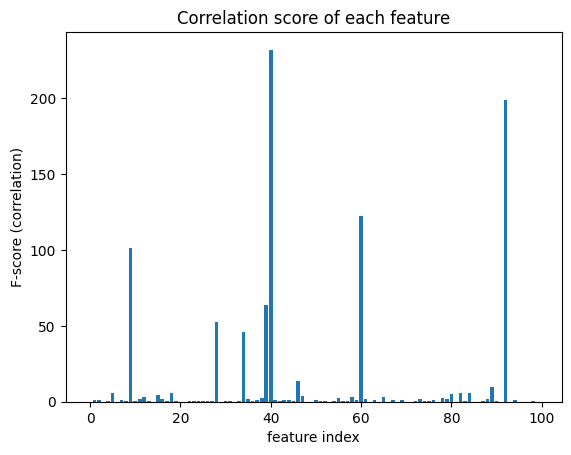

In [3]:
mae_corr, sel_corr = evaluate(f_regression, k=10)
print("MAE correlation, k=10:", round(mae_corr, 3))

plt.bar(range(100), sel_corr.scores_)
plt.xlabel("feature index"); plt.ylabel("F-score (correlation)")
plt.title("Correlation score of each feature")
plt.show()

➡ A few features have a very high score. With only 10 features the MAE is ≈ 2.7 – worse than with all features (≈ 0.09),
because one of the 10 informative features has a weak *individual* correlation with y and is not chosen.

## (b) Selection by mutual information (`mutual_info_regression`)
**Mutual information** measures how much knowing a feature reduces the uncertainty about y.
It can also detect **non-linear** relationships (correlation only sees linear ones). 0 = independent.

MAE mutual information, k=10: 68.21


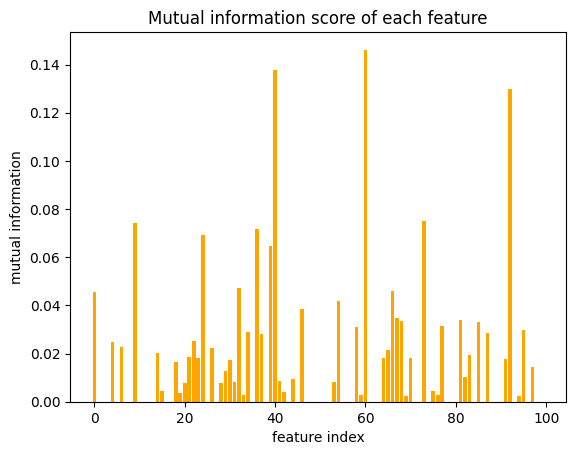

In [4]:
mae_mi, sel_mi = evaluate(mutual_info_regression, k=10)
print("MAE mutual information, k=10:", round(mae_mi, 3))

plt.bar(range(100), sel_mi.scores_, color="orange")
plt.xlabel("feature index"); plt.ylabel("mutual information")
plt.title("Mutual information score of each feature")
plt.show()

## (c) Choosing the number of features k
We run both methods for k = 5, 10, 20, …, 90 and plot the test MAE.

k=  5   correlation MAE= 68.228   mutual info MAE= 78.287
k= 10   correlation MAE=  2.740   mutual info MAE= 68.210
k= 20   correlation MAE=  2.805   mutual info MAE= 62.052
k= 30   correlation MAE=  2.842   mutual info MAE= 44.962
k= 40   correlation MAE=  2.888   mutual info MAE= 44.999
k= 50   correlation MAE=  2.911   mutual info MAE= 17.031
k= 60   correlation MAE=  2.932   mutual info MAE= 17.208
k= 70   correlation MAE=  0.082   mutual info MAE=  0.083
k= 80   correlation MAE=  0.085   mutual info MAE=  0.083
k= 90   correlation MAE=  0.085   mutual info MAE=  0.084


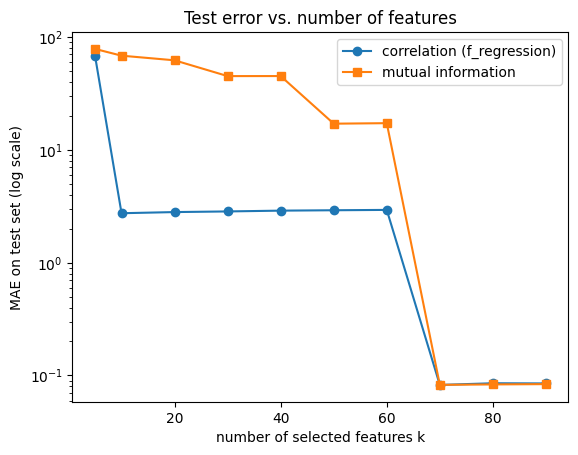

In [5]:
ks = [5, 10, 20, 30, 40, 50, 60, 70, 80, 90]
mae_corr_list = [evaluate(f_regression, k)[0] for k in ks]
mae_mi_list = [evaluate(mutual_info_regression, k)[0] for k in ks]

for k, a, b in zip(ks, mae_corr_list, mae_mi_list):
    print(f"k={k:3d}   correlation MAE={a:7.3f}   mutual info MAE={b:7.3f}")

plt.plot(ks, mae_corr_list, "o-", label="correlation (f_regression)")
plt.plot(ks, mae_mi_list, "s-", label="mutual information")
plt.yscale("log")
plt.xlabel("number of selected features k")
plt.ylabel("MAE on test set (log scale)")
plt.title("Test error vs. number of features")
plt.legend()
plt.show()

## Conclusion
- **Correlation is clearly better**: already at k = 10 its MAE is ≈ 2.7, while mutual information needs k ≥ 50 to get below 20.
  This is expected, because the data was generated by a **linear** model and correlation measures exactly linear relationships.
  Mutual information is more general (also non-linear) but it has to be *estimated* and is noisy, so it ranks some useless features too high.
- Correlation stays at ≈ 2.8 from k = 10 to 60: 9 of the 10 informative features are found early, the 10th one only enters between k = 60 and 70.
- From **k = 70** on both methods reach the minimum error ≈ 0.08 (= the noise level of the data).
- **Which k?** Choose the **smallest k with minimal error → k ≈ 70** (with correlation). More features do not reduce the error anymore,
  fewer features miss an informative one. (A finer search between 60 and 70 could lower k a bit.)